In [1]:
import pandas as pd
import numpy as np

In [3]:
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
df=diabetes.frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [4]:
df.shape

(442, 11)

In [6]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


In [7]:
df.columns

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'target'],
      dtype='object')

In [14]:
#separate x and y
from sklearn.model_selection import train_test_split
x=df.iloc[:,:-1]
y=df.iloc[:,-1]
print(x)
print(y)

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  
0   -0.002592  0.019907 -0.017646  
1  

In [17]:
y

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [19]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
x_train.shape

(309, 10)

In [20]:
#scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

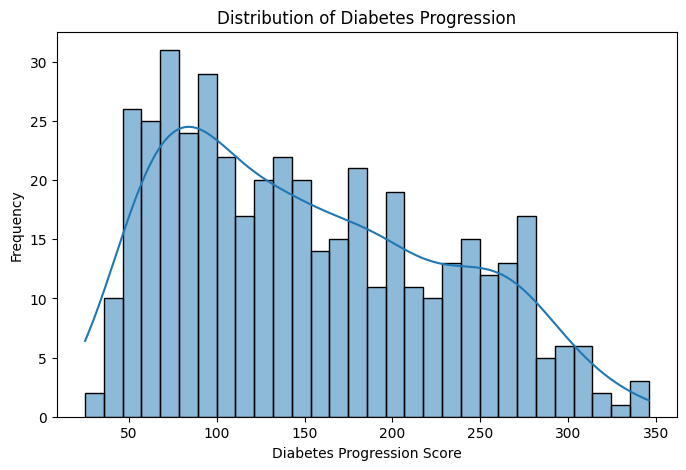

In [21]:
#eda
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.histplot(df["target"],bins=30,kde=True)
plt.title("Distribution of Diabetes Progression")
plt.xlabel("Diabetes Progression Score")
plt.ylabel("Frequency")
plt.show()

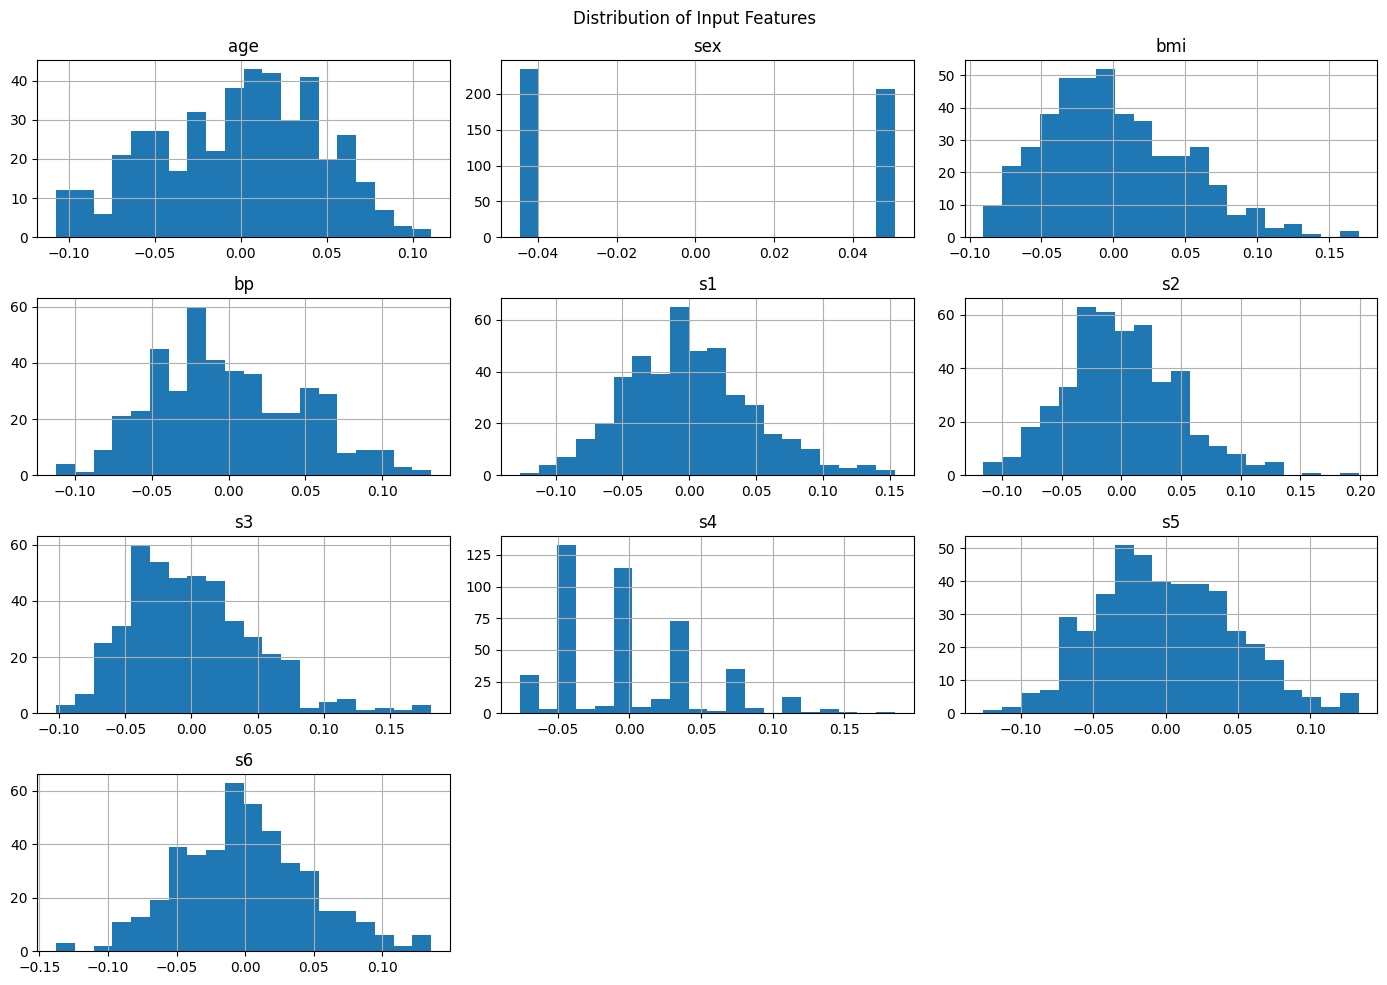

In [22]:
#distribution of input features
x_og=df.drop("target", axis=1)
x_og.hist(figsize=(14, 10),bins=20)
plt.suptitle("Distribution of Input Features")
plt.tight_layout()
plt.show()

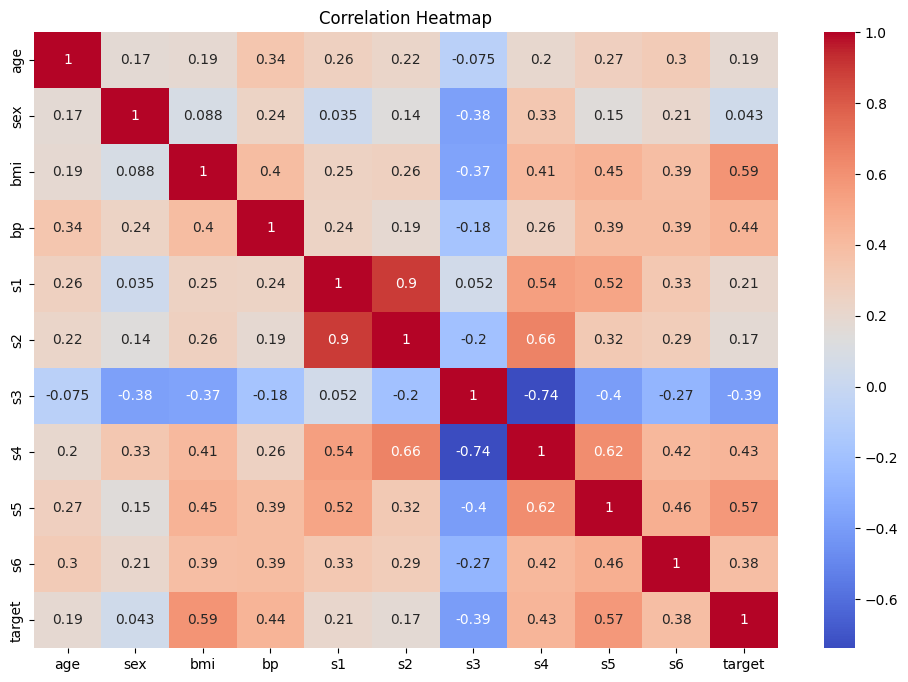

In [23]:
#correlation heatmap
plt.figure(figsize=(12,8))
correlation = df.corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [30]:
#build ANN Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
model=Sequential()
model.add(Dense(128,activation="relu"))
model.add(Dense(128,activation="relu"))
model.add(Dense(64,activation="relu"))
model.add(Dense(32,activation="relu"))
model.add(Dense(1,activation="linear"))

In [32]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [39]:
#compile the model
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

In [40]:
#train the model
history=model.fit(x_train,y_train,epochs=50,batch_size=32,validation_split=0.2)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - loss: 2587.8240 - mae: 40.7937 - val_loss: 3076.3572 - val_mae: 43.4970
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 2428.0044 - mae: 39.8534 - val_loss: 3089.3171 - val_mae: 43.3788
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2428.0696 - mae: 39.6864 - val_loss: 3083.0549 - val_mae: 43.2311
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2416.4058 - mae: 39.5639 - val_loss: 3047.6619 - val_mae: 43.1745
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2403.6367 - mae: 39.5964 - val_loss: 3047.2883 - val_mae: 43.2882
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2396.8315 - mae: 39.4005 - val_loss: 3060.4753 - val_mae: 43.1136
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2381.0386 - mae: 39.3186 - val_loss: 3059.0469 - val_mae: 43.3713
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2389.1240 - mae: 39.1205 - val_loss: 3049.6729 - val_mae: 43.2375
Epoch 9/50
8/8 

In [42]:
#early stoppping
from tensorflow import keras
early_stop=keras.callbacks.EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [43]:
history=model.fit(x_train,y_train,epochs=50,batch_size=32,validation_split=0.2,callbacks=[early_stop])

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 1772.6066 - mae: 32.9102 - val_loss: 3067.1614 - val_mae: 43.3204
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 1760.8929 - mae: 32.7903 - val_loss: 3085.7661 - val_mae: 43.5036
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 1717.5867 - mae: 33.0681 - val_loss: 3099.5754 - val_mae: 43.7374
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1745.3945 - mae: 32.7205 - val_loss: 3065.5388 - val_mae: 43.0555
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 1704.7683 - mae: 32.1799 - val_loss: 3069.8025 - val_mae: 43.2530
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 1683.8536 - mae: 31.9824 - val_loss: 3114.8513 - val_mae: 43.2238
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1654.5592 - mae: 32.2135 - val_loss: 3151.8958 - val_mae: 44.1859
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 1582.6670 - mae: 31.0703 - val_loss: 3082.9072 - val_mae: 43.3513
Epoch 9/50
8/8 ━

In [46]:
y_pred=model.predict(x_test).flatten()

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [47]:
#evaluation metrics
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [48]:
print("Mean Squared Error:",mse)
print("Mean Absolute Error:",mae)
print("R2 Score:",r2)

Mean Squared Error: 3401.0373260697443
Mean Absolute Error: 44.95135721765963
R2 Score: 0.36998083916549807
